<style>
.lab-banner {
  padding: 28px 32px;
  border-radius: 18px;
  background: linear-gradient(120deg, #0f172a, #1d4ed8, #7c3aed);
  color: white;
  margin: 8px 0 22px 0;
  box-shadow: 0 10px 30px rgba(15, 23, 42, .18);
}
.lab-banner h1 { margin: 0 0 8px 0; font-size: 34px; }
.lab-banner p { margin: 5px 0; font-size: 16px; opacity: .95; }
.note-box, .why-box, .warning-box, .result-box {
  padding: 14px 18px; border-radius: 12px; margin: 12px 0;
}
.note-box { background: #eff6ff; border-left: 5px solid #2563eb; }
.why-box { background: #f5f3ff; border-left: 5px solid #7c3aed; }
.warning-box { background: #fff7ed; border-left: 5px solid #ea580c; }
.result-box { background: #ecfdf5; border-left: 5px solid #059669; }
.small-muted { color: #64748b; font-size: 13px; }
</style>

<div class="lab-banner">
  <h1>LAB07 — TEXT CLASSIFICATION · UNIFIED GPU COLAB</h1>
  <p><b>Assignment 1:</b> Phân tích cảm xúc IMDB bằng TensorFlow/Keras</p>
  <p><b>Assignment 2:</b> Phân loại bài báo BBC bằng TF-IDF và Doc2Vec</p>
  <p class="small-muted" style="color:#e2e8f0">Bản hợp nhất duy nhất, tối ưu cho Google Colab GPU: TensorFlow mixed precision, pipeline tf.data có cache/prefetch và XGBoost CUDA với cơ chế tự động fallback CPU.</p>
</div>

### Thông tin sinh viên
- **Họ và tên:** ........................................................
- **MSSV:** ........................................................
- **Lớp:** ........................................................
- **Ngày thực hiện:** ........................................................

## Mục tiêu học tập

Sau khi hoàn thành notebook, người học có thể:

1. Mô tả quy trình phân loại văn bản từ dữ liệu thô đến dự đoán.
2. Phân biệt **tokenization**, **TF-IDF**, **embedding** và **Doc2Vec**.
3. Xây dựng mô hình nhị phân cho IMDB bằng TensorFlow/Keras.
4. Xây dựng mô hình đa lớp cho BBC News bằng scikit-learn, Gensim và XGBoost.
5. Đọc và giải thích đường học, ma trận nhầm lẫn, Accuracy và Macro-F1.
6. Nhận biết các lỗi kỹ thuật thường gặp như API cũ, data leakage và đánh giá chưa đầy đủ.

<div class="why-box"><b>Lý do thiết kế notebook theo dạng này:</b> Bài lab không chỉ cần “chạy ra kết quả” mà còn phải thể hiện người làm hiểu dữ liệu, hiểu mô hình, biết đánh giá và biết giải thích quyết định kỹ thuật.</div>

## Các điểm đã sửa so với tài liệu gốc

| Nội dung cũ | Cách triển khai lại | Lý do |
|---|---|---|
| Cài `tf-nightly` | Dùng TensorFlow ổn định có sẵn trên Colab | Bản nightly thay đổi thường xuyên, dễ lỗi phụ thuộc |
| `imdb_reviews/subwords8k` và `encoder` | `imdb_reviews` + `TextVectorization` | API hiện đại, dễ đóng gói vào mô hình, xử lý văn bản thô trực tiếp |
| Padding thủ công bằng `padded_batch` | `output_sequence_length` trong `TextVectorization` | Luồng dữ liệu đơn giản và nhất quán |
| Chỉ theo dõi Accuracy | Thêm Loss, Macro-F1, classification report và confusion matrix | Accuracy một mình chưa chỉ ra lớp nào bị nhầm |
| Huấn luyện Doc2Vec theo vòng lặp giảm `alpha` thủ công | Dùng API `build_vocab()` và `train()` hiện hành | Phù hợp Gensim 4.x, ít lỗi hơn |
| Dễ vô tình học từ tập kiểm tra | Tách train/test trước khi fit vectorizer/Doc2Vec | Ngăn **data leakage** |
| Không kiểm soát thời gian chạy | Có `QUICK_MODE` | Dễ kiểm thử; có thể chuyển sang chế độ đầy đủ khi nộp |

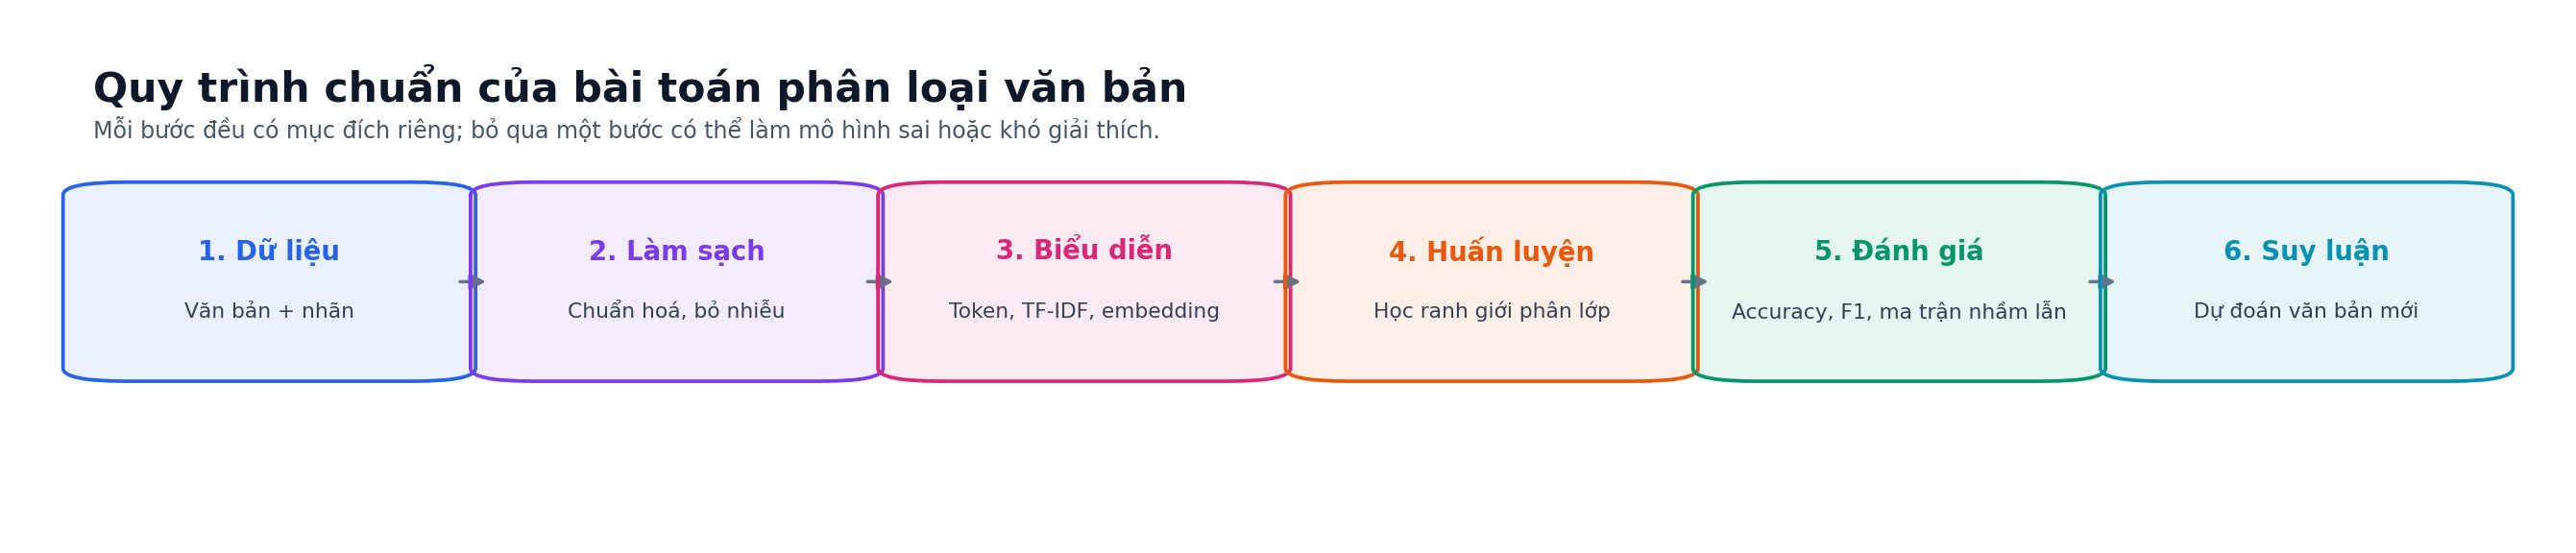

**Giải thích hình:** Văn bản không được đưa thẳng vào thuật toán học máy. Ta cần làm sạch và biến nó thành số. Sau khi mô hình học trên tập huấn luyện, tập kiểm tra chỉ được dùng để ước lượng khả năng tổng quát hoá trên dữ liệu chưa từng thấy.

## 0. Hướng dẫn chạy bản hợp nhất GPU

1. Mở notebook bằng **Google Colab**.
2. Chọn `Runtime → Change runtime type → T4 GPU` (hoặc GPU mạnh hơn nếu tài khoản có).
3. Chọn `Runtime → Run all`; không cần chạy ghép với bất kỳ notebook nào khác.
4. Bản này mặc định `QUICK_MODE = False` để chạy đầy đủ dữ liệu và cấu hình.
5. Khi chỉ cần kiểm tra nhanh luồng code, tạm đổi `QUICK_MODE = True` rồi chạy lại từ đầu.

<div class="warning-box"><b>Lưu ý:</b> TensorFlow và XGBoost sẽ tự dùng GPU khi Colab cấp GPU. Logistic Regression, Random Forest và Gensim Doc2Vec không có backend GPU trong các thư viện đang dùng, nên chúng vẫn tận dụng toàn bộ CPU Colab. Nếu Colab chưa cấp GPU, notebook sẽ cảnh báo và vẫn có thể chạy bằng CPU.</div>


# PHẦN A — CHUẨN BỊ MÔI TRƯỜNG

In [ ]:
# Cài/kiểm tra thư viện theo phiên bản tối thiểu.
# Không dùng "-U" cho toàn bộ môi trường và không ghim các bản cũ,
# nhằm tránh hạ cấp NumPy/SciPy có sẵn trên Google Colab.

import importlib.metadata as metadata
import importlib.util
import subprocess
import sys

# 'packaging' hầu như luôn có sẵn trên Colab (nhiều gói phụ thuộc nó),
# nhưng vẫn tự cài phòng trường hợp môi trường thiếu, tránh crash cell.
try:
    from packaging.version import Version
except ImportError:
    subprocess.check_call(
        [sys.executable, '-m', 'pip', 'install', '-q', 'packaging']
    )
    from packaging.version import Version


PACKAGE_RULES = {
    # module_name: (distribution_name, minimum_version, install_spec)
    'tensorflow': (
        'tensorflow',
        '2.16.0',
        'tensorflow>=2.16,<3',
    ),
    'tensorflow_datasets': (
        'tensorflow-datasets',
        '4.9.0',
        'tensorflow-datasets>=4.9,<5',
    ),
    # Gensim 4.4 tương thích tốt hơn với NumPy/SciPy mới trên Colab.
    'gensim': (
        'gensim',
        '4.4.0',
        'gensim>=4.4,<5',
    ),
    'wordcloud': (
        'wordcloud',
        '1.9.3',
        'wordcloud>=1.9.3,<2',
    ),
    'xgboost': (
        'xgboost',
        '2.1.1',
        'xgboost>=2.1.1,<4',
    ),
}


to_install = []

for module_name, (
    distribution_name,
    minimum_version,
    install_spec,
) in PACKAGE_RULES.items():

    if importlib.util.find_spec(module_name) is None:
        to_install.append(install_spec)
        continue

    try:
        installed_version = metadata.version(distribution_name)
    except metadata.PackageNotFoundError:
        to_install.append(install_spec)
        continue

    if Version(installed_version) < Version(minimum_version):
        to_install.append(install_spec)


if to_install:
    print('Đang cài/cập nhật:', to_install)
    subprocess.check_call([
        sys.executable,
        '-m',
        'pip',
        'install',
        '-q',
        *to_install,
    ])
else:
    print(
        'Các thư viện đã đạt phiên bản tối thiểu; '
        'không thay đổi môi trường Colab.'
    )


# Hiển thị xung đột dependency nếu có, nhưng không tự ý hạ cấp package lõi.
pip_check = subprocess.run(
    [sys.executable, '-m', 'pip', 'check'],
    text=True,
    capture_output=True,
    check=False,
)

print('\npip check:')
print(
    pip_check.stdout.strip()
    or pip_check.stderr.strip()
    or 'Không phát hiện xung đột dependency.'
)


print('\nPhiên bản được sử dụng:')
for _, (
    distribution_name,
    _,
    _,
) in PACKAGE_RULES.items():
    try:
        print(
            f'{distribution_name}: '
            f'{metadata.version(distribution_name)}'
        )
    except metadata.PackageNotFoundError:
        print(f'{distribution_name}: chưa cài')


In [ ]:
import os
import re
import string
import time
import random
import warnings
import zlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, mixed_precision
import tensorflow_datasets as tfds

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
)
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

from gensim.models.doc2vec import Doc2Vec, TaggedDocument
from gensim.utils import simple_preprocess
from wordcloud import WordCloud
from xgboost import XGBClassifier

# Không ẩn toàn bộ warning: warning hội tụ hoặc dependency có thể rất hữu ích.
warnings.filterwarnings('default')

print('TensorFlow:', tf.__version__)
print('TensorFlow Datasets:', tfds.__version__)


In [ ]:
# =========================
# CẤU HÌNH THÍ NGHIỆM + GPU
# =========================

SEED = 42

# False = chạy đầy đủ để lấy kết quả cuối.
# True  = chỉ kiểm tra nhanh toàn bộ pipeline.
QUICK_MODE = False

CPU_WORKERS = max(1, os.cpu_count() or 1)
DOC2VEC_WORKERS = CPU_WORKERS

# Phát hiện GPU trước khi tạo model/tensor lớn.
GPU_DEVICES = tf.config.list_physical_devices('GPU')
GPU_AVAILABLE = len(GPU_DEVICES) > 0

if GPU_AVAILABLE:
    for gpu in GPU_DEVICES:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            # GPU đã được khởi tạo trước đó; tiếp tục với cấu hình hiện tại.
            pass

    # mixed_float16 tăng tốc đáng kể trên GPU Colab có Tensor Cores.
    mixed_precision.set_global_policy('mixed_float16')

    try:
        tf.config.experimental.enable_tensor_float_32_execution(True)
    except Exception:
        pass
else:
    mixed_precision.set_global_policy('float32')

# Cố định seed nhưng KHÔNG bật deterministic ops,
# vì deterministic kernels thường làm GPU chậm hơn và có thể thiếu hỗ trợ.
keras.utils.set_random_seed(SEED)

# Gensim có thể dùng hàm hash khi khởi tạo trọng số.
def stable_hash(value):
    return zlib.crc32(str(value).encode('utf-8'))

# Kiểm tra XGBoost CUDA bằng một bài toán rất nhỏ.
# Nếu wheel/runtime không hỗ trợ CUDA, tự động chuyển về CPU.
XGB_DEVICE = 'cpu'

if GPU_AVAILABLE:
    try:
        _xgb_probe = XGBClassifier(
            n_estimators=1,
            max_depth=1,
            tree_method='hist',
            device='cuda',
            random_state=SEED,
            verbosity=0,
        )
        _xgb_probe.fit(
            np.array([[0.0], [1.0], [0.1], [0.9]], dtype=np.float32),
            np.array([0, 1, 0, 1], dtype=np.int32),
        )
        XGB_DEVICE = 'cuda'
        del _xgb_probe
    except Exception as exc:
        print('XGBoost CUDA không khả dụng, chuyển sang CPU:', exc)

print('Chế độ:', 'NHANH' if QUICK_MODE else 'ĐẦY ĐỦ')
print('CPU workers:', CPU_WORKERS)
print('TensorFlow GPU:', GPU_AVAILABLE)
print('GPU devices:', GPU_DEVICES if GPU_AVAILABLE else 'Không có')
print('Mixed precision policy:', mixed_precision.global_policy())
print('XGBoost device:', XGB_DEVICE)

if not GPU_AVAILABLE:
    print(
        '\nCẢNH BÁO: Colab chưa cấp GPU. '
        'Hãy chọn Runtime → Change runtime type → T4 GPU rồi Run all lại.'
    )


<div class="why-box"><b>Tại sao cần cố định seed?</b> Một số bước như chia dữ liệu, khởi tạo trọng số và lấy mẫu có yếu tố ngẫu nhiên. Cố định seed giúp kết quả dễ tái lập, thuận tiện khi so sánh mô hình hoặc viết báo cáo.</div>

# PHẦN B — ASSIGNMENT 1: IMDB MOVIE REVIEWS

## 1. Bài toán và lý thuyết nền

Mỗi review được gán một trong hai nhãn:

- `0`: cảm xúc **tiêu cực**
- `1`: cảm xúc **tích cực**

Đây là bài toán **binary classification**. Mô hình trả về xác suất $p(y=1\mid x)$ bằng hàm sigmoid. Hàm mất mát thường dùng là Binary Cross-Entropy:

$$
\mathcal{L}=-\frac{1}{N}\sum_{i=1}^{N}\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right]
$$

Loss phạt mạnh khi mô hình dự đoán rất tự tin nhưng sai.

## 2. Tải và chia dữ liệu IMDB

Bộ IMDB có 25.000 review huấn luyện và 25.000 review kiểm tra. Ta tách 20% tập train thành validation:

- **Train:** cập nhật trọng số.
- **Validation:** chọn epoch và phát hiện overfitting.
- **Test:** đánh giá cuối cùng; không dùng để điều chỉnh mô hình.

<div class="why-box"><b>Lý do tách ba tập:</b> Nếu vừa nhìn kết quả test vừa sửa mô hình, tập test không còn đại diện cho dữ liệu hoàn toàn mới nữa.</div>

In [ ]:
(train_raw, val_raw, test_raw), imdb_info = tfds.load(
    'imdb_reviews',
    split=['train[:80%]', 'train[80%:]', 'test'],
    as_supervised=True,
    with_info=True,
)

# QUICK_MODE dùng mẫu nhỏ hơn để kiểm thử notebook nhanh.
if QUICK_MODE:
    train_raw = train_raw.shuffle(20_000, seed=SEED, reshuffle_each_iteration=False).take(6_000)
    val_raw = val_raw.shuffle(5_000, seed=SEED, reshuffle_each_iteration=False).take(1_500)
    test_raw = test_raw.shuffle(25_000, seed=SEED, reshuffle_each_iteration=False).take(2_500)

print(imdb_info)

In [ ]:
def tf_dataset_to_frame(dataset, max_items=2_000):
    rows = []
    for text, label in tfds.as_numpy(dataset.take(max_items)):
        decoded = text.decode('utf-8') if isinstance(text, bytes) else str(text)
        rows.append({'text': decoded, 'label': int(label)})
    return pd.DataFrame(rows)

imdb_preview = tf_dataset_to_frame(train_raw, max_items=2_000)
imdb_preview['sentiment'] = imdb_preview['label'].map({0: 'Negative', 1: 'Positive'})
imdb_preview['word_count'] = imdb_preview['text'].str.split().str.len()

print('Số mẫu dùng để khám phá:', len(imdb_preview))
display(imdb_preview.head(3))

## 3. Khám phá dữ liệu IMDB

Ta kiểm tra phân bố nhãn và độ dài review trước khi chọn cấu hình mô hình.

- Nếu nhãn lệch mạnh, Accuracy có thể gây hiểu nhầm.
- Độ dài review giúp chọn `output_sequence_length`: quá ngắn làm mất thông tin, quá dài làm tăng thời gian và bộ nhớ.

In [ ]:
label_counts = imdb_preview['sentiment'].value_counts().sort_index()

plt.figure(figsize=(7, 4))
label_counts.plot(kind='bar')
plt.title('Phân bố nhãn trong mẫu IMDB')
plt.xlabel('Nhãn cảm xúc')
plt.ylabel('Số review')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8, 4.5))
plt.hist(imdb_preview['word_count'], bins=40)
plt.axvline(imdb_preview['word_count'].median(), linestyle='--', label='Trung vị')
plt.title('Phân bố độ dài review IMDB')
plt.xlabel('Số từ trong review')
plt.ylabel('Tần suất')
plt.legend()
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print(imdb_preview['word_count'].describe(percentiles=[0.5, 0.75, 0.9, 0.95]))

<div class="result-box"><b>Cách đọc biểu đồ:</b> Đường đứt là độ dài trung vị. Phần đuôi bên phải cho thấy một số review rất dài. Ta không nhất thiết giữ toàn bộ chiều dài; giới hạn chuỗi là sự đánh đổi giữa lượng thông tin và chi phí tính toán.</div>

In [ ]:
# Xem một số ví dụ để hiểu dữ liệu thật sự chứa gì.
for idx, row in imdb_preview.sample(3, random_state=SEED).iterrows():
    print('=' * 100)
    print('Nhãn:', row['sentiment'])
    print(row['text'][:700], '...')

## 4. Chuẩn hoá và vector hoá văn bản

Máy học không hiểu trực tiếp chuỗi ký tự. `TextVectorization` thực hiện:

1. Viết thường.
2. Bỏ thẻ HTML như `<br />`.
3. Bỏ dấu câu.
4. Tách từ.
5. Ánh xạ từ sang chỉ số nguyên.
6. Cắt hoặc padding chuỗi về cùng chiều dài.

Các token đặc biệt thường gồm:

- `""`: padding.
- `[UNK]`: từ không có trong từ điển.

<div class="why-box"><b>Tại sao dùng TextVectorization thay encoder cũ?</b> Lớp này là một phần của mô hình Keras, có thể nhận văn bản thô khi dự đoán và giảm nguy cơ preprocessing lúc train khác preprocessing lúc triển khai.</div>

In [ ]:
MAX_TOKENS = 20_000 if QUICK_MODE else 30_000
SEQUENCE_LENGTH = 250
EMBEDDING_DIM = 96 if QUICK_MODE else 128

@keras.utils.register_keras_serializable()
def custom_standardization(text):
    text = tf.strings.lower(text)
    text = tf.strings.regex_replace(text, r'<br\s*/?>', ' ')
    return tf.strings.regex_replace(
        text,
        f'[{re.escape(string.punctuation)}]',
        ''
    )

vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    standardize=custom_standardization,
    output_mode='int',
    output_sequence_length=SEQUENCE_LENGTH,
    name='text_vectorization',
)

# Chỉ học từ điển từ tập train để tránh data leakage.
# Batch lớn + prefetch giúp phần chuẩn bị dữ liệu không làm GPU phải chờ.
adapt_text_ds = (
    train_raw
    .map(lambda text, label: text, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(1024)
    .prefetch(tf.data.AUTOTUNE)
)
vectorizer.adapt(adapt_text_ds)

vocabulary = vectorizer.get_vocabulary()
print('Kích thước từ điển thực tế:', len(vocabulary))
print('20 token đầu:', vocabulary[:20])


In [ ]:
# Minh hoạ một review được biến thành dãy số như thế nào.
sample_text = imdb_preview.iloc[0]['text']
sample_ids = vectorizer(tf.constant([sample_text]))[0].numpy()

rows = []
for position, token_id in enumerate(sample_ids[:40]):
    token = vocabulary[token_id] if token_id < len(vocabulary) else '[OUT]'
    rows.append({'Vị trí': position, 'Token ID': int(token_id), 'Token': token})

print('Văn bản mẫu:')
print(sample_text[:500], '...')
display(pd.DataFrame(rows))

<div class="note-box"><b>Giải thích bảng token:</b> Mỗi từ đã trở thành một số nguyên. Các số này chưa mang ý nghĩa “gần/xa”; lớp Embedding ở bước kế tiếp sẽ học vector liên tục cho từng token.</div>

## 5. Kiến trúc mô hình GPU


### Vai trò từng lớp

- **TextVectorization (tiền xử lý):** đổi chuỗi thành dãy token ID trước khi batch được đưa vào model.
- **Embedding:** học vector cho mỗi token.
- **SpatialDropout1D:** bỏ đồng thời một số chiều embedding để giảm overfitting.
- **Conv1D:** học các mẫu từ/cụm từ cục bộ và khai thác GPU tốt hơn mô hình Dense rất nhỏ.
- **GlobalMaxPooling1D:** giữ đặc trưng mạnh nhất trên toàn review.
- **Dense + Dropout:** kết hợp đặc trưng và giảm học thuộc.
- **Sigmoid `float32`:** trả xác suất ổn định ngay cả khi các lớp trước chạy mixed precision.

<div class="why-box"><b>Lý do dùng TextCNN:</b> Mô hình vẫn dễ giải thích cho bài lab nhưng có phép tích chập đủ lớn để tận dụng GPU Colab. Mixed precision giảm bộ nhớ và tăng tốc trên GPU có Tensor Cores.</div>

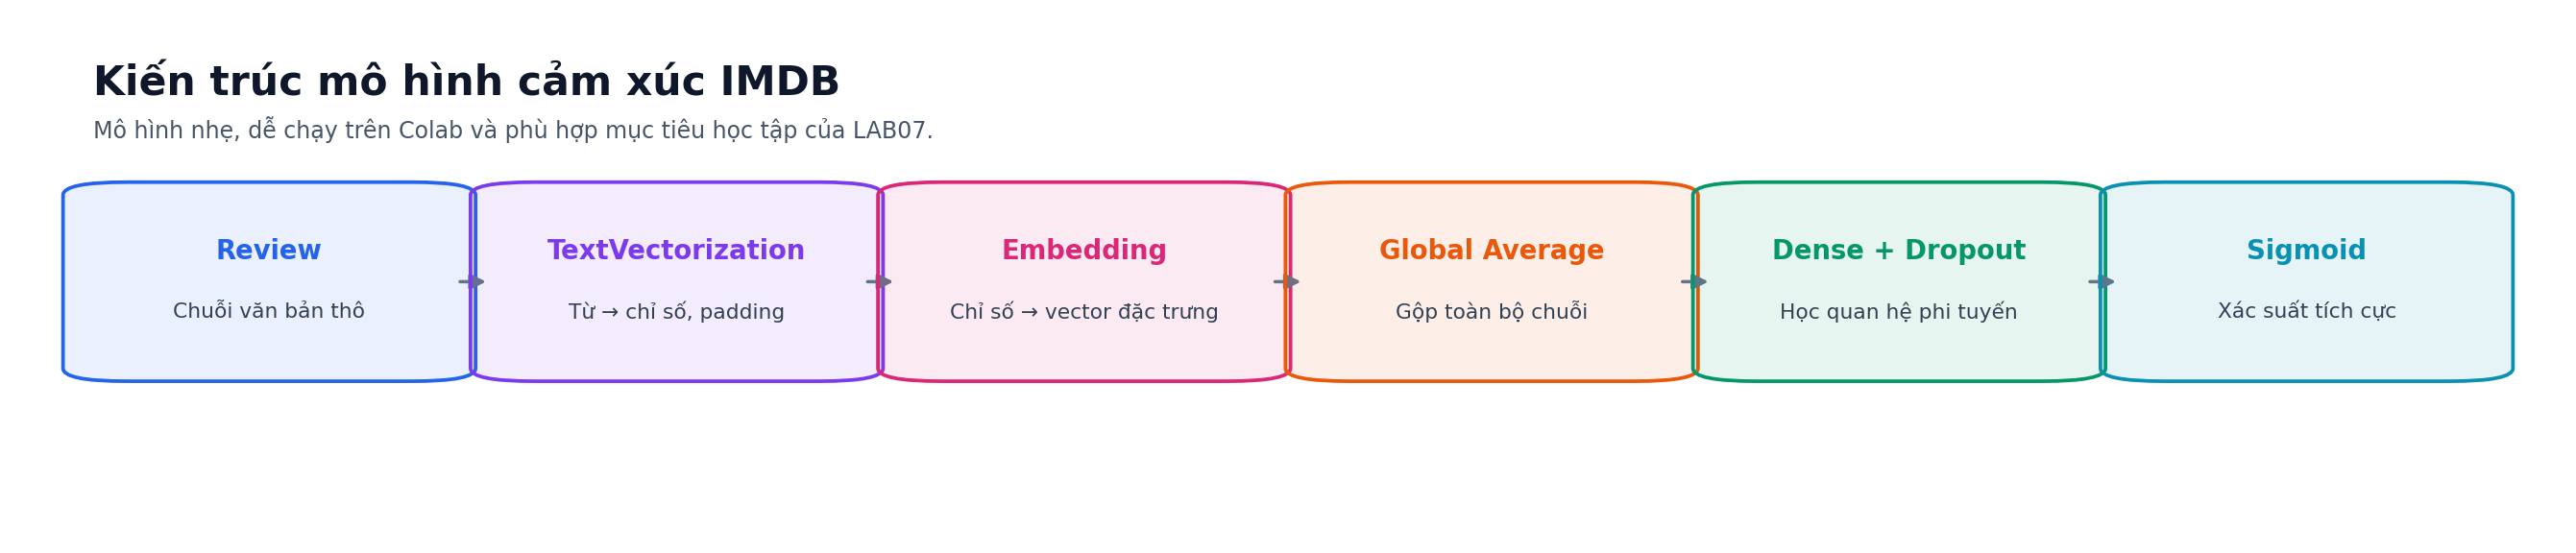

In [ ]:
# Model nhận token ID đã vector hoá để GPU không phải chờ xử lý chuỗi.
inputs = keras.Input(
    shape=(SEQUENCE_LENGTH,),
    dtype=tf.int64,
    name='token_ids',
)

x = layers.Embedding(
    input_dim=len(vocabulary),
    output_dim=EMBEDDING_DIM,
    name='embedding',
)(inputs)

x = layers.SpatialDropout1D(0.20, name='spatial_dropout')(x)
x = layers.Conv1D(
    filters=128,
    kernel_size=5,
    padding='same',
    activation='relu',
    name='text_conv',
)(x)
x = layers.GlobalMaxPooling1D(name='global_max_pooling')(x)
x = layers.Dense(128, activation='relu', name='dense_features')(x)
x = layers.Dropout(0.40, name='dropout')(x)

# Ép output về float32 để loss/metric ổn định với mixed_float16.
outputs = layers.Dense(
    1,
    activation='sigmoid',
    dtype='float32',
    name='positive_probability',
)(x)

imdb_model = keras.Model(
    inputs,
    outputs,
    name='imdb_textcnn_gpu',
)

imdb_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name='accuracy')],
    steps_per_execution=32 if GPU_AVAILABLE else 1,
)

imdb_model.summary()


## 6. Chuẩn bị pipeline `tf.data` tối ưu GPU

- `map(vectorizer, num_parallel_calls=AUTOTUNE)`: vector hoá song song trên CPU.
- `cache`: lưu token ID sau lần đầu, tránh vector hoá lại ở mỗi epoch.
- `shuffle`: thay đổi thứ tự train mỗi epoch.
- `batch`: batch 256 trên GPU để tăng lượng phép tính song song.
- `prefetch(AUTOTUNE)`: chuẩn bị batch kế tiếp trong khi GPU đang huấn luyện batch hiện tại.

<div class="why-box"><b>Tách vectorizer khỏi model:</b> Xử lý chuỗi thường chạy trên CPU. Vector hoá và cache trước giúp GPU nhận tensor số liên tục, giảm thời gian chờ dữ liệu.</div>


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 256 if GPU_AVAILABLE else 64

def vectorize_example(text, label):
    token_ids = vectorizer(text)
    return token_ids, tf.cast(label, tf.float32)

data_options = tf.data.Options()
# Tắt ép thứ tự xác định để map/prefetch được chạy song song tối đa.
data_options.experimental_deterministic = False

train_vectorized = (
    train_raw
    .map(
        vectorize_example,
        num_parallel_calls=AUTOTUNE,
        deterministic=False,
    )
    .cache()
    .with_options(data_options)
)

val_vectorized = (
    val_raw
    .map(vectorize_example, num_parallel_calls=AUTOTUNE)
    .cache()
)

test_vectorized = (
    test_raw
    .map(vectorize_example, num_parallel_calls=AUTOTUNE)
    .cache()
)

train_ds = (
    train_vectorized
    .shuffle(25_000, seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
val_ds = val_vectorized.batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = test_vectorized.batch(BATCH_SIZE).prefetch(AUTOTUNE)

for token_batch, label_batch in train_ds.take(1):
    print('Token batch shape:', token_batch.shape)
    print('Label batch shape:', label_batch.shape)
    print('Batch size:', BATCH_SIZE)


## 7. Huấn luyện

Ta dùng hai callback:

- **EarlyStopping:** dừng khi validation loss không còn tốt hơn, đồng thời khôi phục trọng số tốt nhất.
- **ReduceLROnPlateau:** giảm learning rate khi mô hình chững lại.

<div class="why-box"><b>Lý do theo dõi `val_loss`:</b> Training loss thường tiếp tục giảm ngay cả khi mô hình bắt đầu học thuộc. Validation loss phản ánh tốt hơn khả năng tổng quát hoá.</div>

In [ ]:
EPOCHS = 4 if QUICK_MODE else 12

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=1,
        min_lr=1e-6,
        verbose=1,
    ),
]

history = imdb_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)


## 8. Phân tích đường học

- **Loss giảm:** dự đoán đang tiến gần nhãn thật.
- **Accuracy tăng:** tỷ lệ dự đoán đúng tăng.
- **Train tiếp tục tốt lên nhưng validation xấu đi:** dấu hiệu overfitting.
- **Cả train và validation đều kém:** có thể underfitting hoặc preprocessing chưa phù hợp.

In [ ]:
history_df = pd.DataFrame(history.history)
history_df.index = np.arange(1, len(history_df) + 1)

display(history_df)

plt.figure(figsize=(8, 4.5))
plt.plot(history_df.index, history_df['loss'], marker='o', label='Training loss')
plt.plot(history_df.index, history_df['val_loss'], marker='o', label='Validation loss')
plt.title('IMDB — Loss theo epoch')
plt.xlabel('Epoch')
plt.ylabel('Binary cross-entropy')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8, 4.5))
plt.plot(history_df.index, history_df['accuracy'], marker='o', label='Training accuracy')
plt.plot(history_df.index, history_df['val_accuracy'], marker='o', label='Validation accuracy')
plt.title('IMDB — Accuracy theo epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Đánh giá trên tập test

Tập test chỉ được dùng sau khi hoàn tất thiết kế và huấn luyện. Ngoài Accuracy, ta xem:

- **Precision:** trong các mẫu mô hình dự đoán thuộc lớp đó, bao nhiêu mẫu đúng.
- **Recall:** trong các mẫu thật sự thuộc lớp đó, mô hình tìm ra bao nhiêu.
- **F1-score:** trung bình điều hoà của Precision và Recall.
- **Confusion matrix:** số lượng dự đoán đúng/sai theo từng hướng.

In [ ]:
test_loss, test_accuracy = imdb_model.evaluate(test_ds, verbose=0)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.4f}')

y_true_imdb = np.concatenate([
    labels.numpy()
    for _, labels in test_ds
])
y_prob_imdb = imdb_model.predict(test_ds, verbose=0).ravel()
y_pred_imdb = (y_prob_imdb >= 0.5).astype(int)

print('\nClassification report:')
print(classification_report(
    y_true_imdb,
    y_pred_imdb,
    labels=[0, 1],
    target_names=['Negative', 'Positive'],
    digits=4,
    zero_division=0,
))


In [ ]:
cm_imdb = confusion_matrix(y_true_imdb, y_pred_imdb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_imdb,
    display_labels=['Negative', 'Positive'],
)
disp.plot(values_format='d')
plt.title('IMDB — Ma trận nhầm lẫn')
plt.tight_layout()
plt.show()

<div class="result-box"><b>Cách đọc ma trận:</b> Hai ô trên đường chéo là dự đoán đúng. Ô ngoài đường chéo cho biết review tiêu cực bị đoán thành tích cực và ngược lại. Khi viết báo cáo, cần nêu loại lỗi nào nhiều hơn và giả thuyết nguyên nhân.</div>

## 10. Thử dự đoán câu mới

In [ ]:
new_reviews = np.array([
    'This movie was touching, beautifully acted and absolutely worth watching.',
    'The plot was boring, the dialogue was weak and I regret watching it.',
    'The film starts slowly but the ending is surprisingly good.',
])

new_review_ids = vectorizer(tf.constant(new_reviews))
probs = imdb_model.predict(
    new_review_ids,
    batch_size=BATCH_SIZE,
    verbose=0,
).ravel()

pred_table = pd.DataFrame({
    'Review': new_reviews,
    'P(Positive)': probs,
    'Dự đoán': np.where(probs >= 0.5, 'Positive', 'Negative'),
})
display(pred_table)


### Nhận xét Assignment 1

Điền sau khi chạy chế độ đầy đủ:

- Test Accuracy: **...............**
- Lớp có Recall thấp hơn: **...............**
- Khoảng cách train/validation ở epoch cuối: **...............**
- Dấu hiệu overfitting: **Có / Không**, vì **........................................................**
- Một hạn chế của TextCNN: kernel tích chập chủ yếu học mẫu cục bộ, nên quan hệ rất dài trong review vẫn có thể chưa được biểu diễn đầy đủ.


# PHẦN C — ASSIGNMENT 2: BBC NEWS ARTICLES

## 11. Bài toán đa lớp

Dữ liệu BBC gồm các bài báo thuộc 5 chủ đề:

- `business`
- `entertainment`
- `politics`
- `sport`
- `tech`

Đây là **multiclass classification**: mỗi bài chỉ thuộc một lớp. Ta so sánh hai cách biểu diễn:

1. **TF-IDF:** vector thưa dựa trên mức độ quan trọng của từ/ngữ.
2. **Doc2Vec:** vector dày học biểu diễn cho toàn tài liệu.

Sau đó thử Logistic Regression, Random Forest và XGBoost.

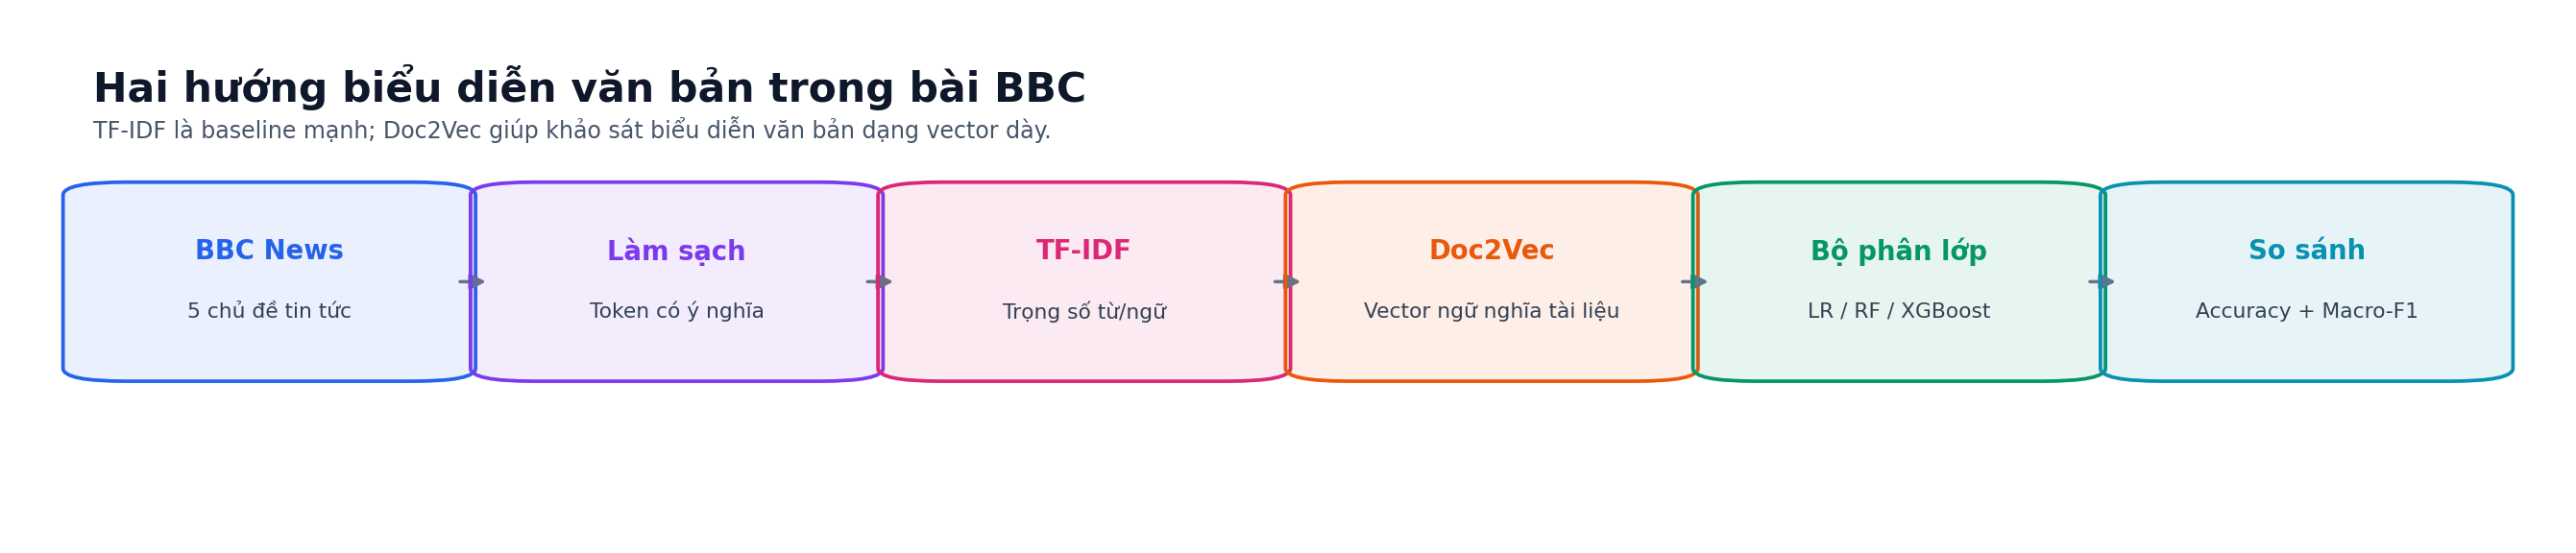

**Giải thích hình:** TF-IDF và Doc2Vec trả lời hai câu hỏi khác nhau. TF-IDF nhấn mạnh “từ nào đặc trưng cho tài liệu”, còn Doc2Vec cố học một vector liên tục tóm tắt tài liệu. So sánh cả hai giúp đánh giá liệu biểu diễn phức tạp hơn có thực sự tốt hơn trên bộ dữ liệu nhỏ.

## 12. Tải và kiểm tra dữ liệu BBC

In [ ]:
BBC_URL = 'https://storage.googleapis.com/dataset-uploader/bbc/bbc-text.csv'

try:
    bbc_df = pd.read_csv(BBC_URL)
except Exception as download_error:
    print('Không tải được BBC CSV từ Internet:', download_error)
    print('Hãy tải file bbc-text.csv lên phiên làm việc.')
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_files = [name for name in uploaded if name.lower().endswith('.csv')]
        if not csv_files:
            raise ValueError('Chưa có file CSV nào được tải lên.')
        bbc_df = pd.read_csv(csv_files[0])
    except ImportError as exc:
        raise RuntimeError(
            'Môi trường hiện tại không phải Colab. Hãy tải bbc-text.csv về máy '
            'và thay BBC_URL bằng đường dẫn cục bộ.'
        ) from exc

required_columns = {'category', 'text'}
if not required_columns.issubset(bbc_df.columns):
    raise ValueError(f'Dữ liệu thiếu cột bắt buộc: {required_columns - set(bbc_df.columns)}')

print('Kích thước ban đầu:', bbc_df.shape)
display(bbc_df.head())

In [ ]:
quality_report = pd.DataFrame({
    'Số giá trị thiếu': bbc_df[['category', 'text']].isna().sum(),
    'Số giá trị duy nhất': bbc_df[['category', 'text']].nunique(),
})

display(quality_report)
print('Số dòng trùng hoàn toàn:', bbc_df.duplicated().sum())

bbc_df = (
    bbc_df[['category', 'text']]
    .dropna()
    .drop_duplicates()
    .reset_index(drop=True)
)

print('Kích thước sau làm sạch cấu trúc:', bbc_df.shape)

<div class="why-box"><b>Tại sao kiểm tra thiếu và trùng?</b> Dòng thiếu không thể dùng trực tiếp; dòng trùng có thể làm mô hình “nhìn thấy lại” cùng nội dung ở train và test, khiến kết quả cao giả tạo.</div>

In [ ]:
category_counts = bbc_df['category'].value_counts().sort_values(ascending=False)

plt.figure(figsize=(8, 4.5))
category_counts.plot(kind='bar')
plt.title('BBC News — Phân bố chủ đề')
plt.xlabel('Chủ đề')
plt.ylabel('Số bài báo')
plt.xticks(rotation=25, ha='right')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print(category_counts)

In [ ]:
bbc_df['word_count'] = bbc_df['text'].str.split().str.len()

plt.figure(figsize=(8, 4.5))
plt.hist(bbc_df['word_count'], bins=40)
plt.axvline(bbc_df['word_count'].median(), linestyle='--', label='Trung vị')
plt.title('BBC News — Phân bố độ dài bài báo')
plt.xlabel('Số từ')
plt.ylabel('Tần suất')
plt.legend()
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print(bbc_df['word_count'].describe(percentiles=[0.5, 0.75, 0.9, 0.95]))

## 13. Làm sạch văn bản BBC

Hàm bên dưới:

1. Viết thường và bỏ dấu Unicode.
2. Tách từ bằng `simple_preprocess`.
3. Bỏ stopword tiếng Anh.
4. Bỏ token quá ngắn.

Notebook **không stemming mặc định** vì từ bị cắt gốc thường khó đọc trên WordCloud và có thể làm mất sắc thái tên riêng/chủ đề. Có thể thử stemming như một thí nghiệm riêng.

<div class="why-box"><b>Lý do phải fit preprocessing chỉ trên train:</b> Các phép “học” như xây vocabulary, IDF hay Doc2Vec không được quan sát test. Hàm làm sạch theo quy tắc cố định thì có thể áp dụng giống nhau cho mọi tập.</div>

In [ ]:
STOPWORDS = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    tokens = simple_preprocess(
        str(text),
        deacc=True,     # bỏ dấu Unicode
        min_len=2,
        max_len=30,
    )
    tokens = [token for token in tokens if token not in STOPWORDS]
    return ' '.join(tokens)

bbc_df['clean_text'] = bbc_df['text'].map(clean_text)

example_idx = 2
print('TRƯỚC LÀM SẠCH:\n', bbc_df.loc[example_idx, 'text'][:800])
print('\nSAU LÀM SẠCH:\n', bbc_df.loc[example_idx, 'clean_text'][:800])

## 14. WordCloud — trực quan hoá từ nổi bật

WordCloud làm từ xuất hiện nhiều có kích thước lớn hơn. Đây là công cụ **khám phá**, không phải bằng chứng định lượng về khả năng dự đoán.

<div class="warning-box"><b>Cẩn thận khi diễn giải:</b> Tần suất cao không đồng nghĩa với quan hệ nhân quả. WordCloud cũng không thể hiện tốt ngữ cảnh, phủ định hoặc cụm từ dài.</div>

In [ ]:
def plot_wordcloud(text, title):
    cloud = WordCloud(
        width=1200,
        height=600,
        background_color='white',
        collocations=False,
        random_state=SEED,
    ).generate(text)

    plt.figure(figsize=(13, 6))
    plt.imshow(cloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.show()

all_bbc_text = ' '.join(bbc_df['clean_text'])
plot_wordcloud(all_bbc_text, 'BBC News — WordCloud toàn bộ dữ liệu')

In [ ]:
# Tạo WordCloud riêng cho từng chủ đề.
for category in sorted(bbc_df['category'].unique()):
    category_text = ' '.join(
        bbc_df.loc[bbc_df['category'] == category, 'clean_text']
    )
    plot_wordcloud(category_text, f'BBC News — Từ nổi bật của chủ đề: {category}')

### Gợi ý nhận xét WordCloud

- `sport` thường có từ liên quan trận đấu, đội tuyển, cầu thủ hoặc giải đấu.
- `business` thường chứa từ liên quan công ty, thị trường, tăng trưởng, giá và kinh tế.
- `tech` thường có từ về phần mềm, internet, thiết bị hoặc người dùng.
- Các từ xuất hiện ở nhiều lớp ít có giá trị phân biệt hơn từ đặc trưng riêng cho một lớp.

Hãy thay nhận xét tổng quát trên bằng từ cụ thể quan sát được sau khi chạy notebook.

## 15. Chia development/final test có phân tầng

Ta giữ riêng **final test** ngay từ đầu. Tập này không được dùng để:

- chọn mô hình;
- điều chỉnh hyperparameter;
- xây vocabulary hoặc IDF;
- huấn luyện Doc2Vec;
- đánh giá lặp lại.

Phần còn lại gọi là **development set**. Development set tiếp tục được chia thành train/validation để minh hoạ từng mô hình, đồng thời được dùng cho repeated holdout ở mục 20b.

`stratify=y` giúp tỷ lệ 5 lớp trong các tập gần giống dữ liệu gốc.

<div class="why-box"><b>Lý do giữ final test:</b> Nếu vừa dùng test để chọn mô hình vừa báo cáo điểm trên chính test đó, kết quả sẽ lạc quan. Final test chỉ được mở đúng một lần sau khi đã chọn mô hình bằng development set.</div>


In [ ]:
label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(bbc_df['category'])
X_all = bbc_df['clean_text'].to_numpy()


# ==================================================
# BƯỚC 1: GIỮ RIÊNG FINAL TEST
# ==================================================
X_dev, X_final_test_text, y_dev, y_final_test = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    random_state=SEED,
    stratify=y_all,
)


# ==================================================
# BƯỚC 2: CHIA DEVELOPMENT SET THÀNH TRAIN/VALIDATION
# ==================================================
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_dev,
    y_dev,
    test_size=0.20,
    random_state=SEED,
    stratify=y_dev,
)


print('Classes:', list(label_encoder.classes_))
print(
    'Train:', len(X_train_text),
    '| Validation:', len(X_test_text),
    '| Final test:', len(X_final_test_text),
)


split_distribution = pd.DataFrame({
    'Train': pd.Series(
        label_encoder.inverse_transform(y_train)
    ).value_counts(normalize=True),

    'Validation': pd.Series(
        label_encoder.inverse_transform(y_test)
    ).value_counts(normalize=True),

    'Final test': pd.Series(
        label_encoder.inverse_transform(y_final_test)
    ).value_counts(normalize=True),
}).fillna(0)


display(split_distribution)


## 16. Mô hình baseline: TF-IDF + Logistic Regression

TF-IDF giảm trọng số của từ xuất hiện ở quá nhiều tài liệu và tăng trọng số cho từ đặc trưng.

Với `sublinear_tf=True`, tần suất từ được biến đổi:

$$
\mathrm{tf}_{\log}(t,d)=
\begin{cases}
1+\log(\mathrm{count}(t,d)), & \mathrm{count}(t,d)>0 \\
0, & \text{ngược lại}
\end{cases}
$$

Với `smooth_idf=True` mặc định của scikit-learn:

$$
\mathrm{idf}(t)
=
\log\left(
\frac{1+N}{1+\mathrm{df}(t)}
\right)+1
$$

Do đó:

$$
\mathrm{tfidf}(t,d)
=
\mathrm{tf}_{\log}(t,d)\times\mathrm{idf}(t)
$$

Ta dùng cả unigram và bigram để mô hình có thể học cụm hai từ. Logistic Regression là baseline mạnh cho vector thưa, nhiều chiều.

### Cross-validation

Tập train được chia thành nhiều fold. Mỗi lượt dùng một fold để validation và phần còn lại để train. TF-IDF nằm **bên trong Pipeline**, vì vậy vocabulary và IDF được fit lại riêng trong từng fold, tránh data leakage.


In [ ]:
tfidf_lr = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        max_features=20_000 if QUICK_MODE else 50_000,
        sublinear_tf=True,
    )),
    ('classifier', LogisticRegression(
        max_iter=1_500,
        class_weight='balanced',
        random_state=SEED,
    )),
])

cv = StratifiedKFold(
    n_splits=3 if QUICK_MODE else 5,
    shuffle=True,
    random_state=SEED,
)

cv_scores = cross_val_score(
    tfidf_lr,
    X_train_text,
    y_train,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
)

print('TF-IDF + Logistic Regression CV scores:', np.round(cv_scores, 4))
print(f'CV mean: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')

<div class="result-box"><b>Cách đọc CV:</b> Trung bình cho biết hiệu năng điển hình; độ lệch chuẩn nhỏ cho thấy kết quả ít phụ thuộc vào cách chia fold. CV ở đây chỉ dùng trên tập train để kiểm tra baseline. Việc chọn mô hình cuối cùng sẽ dựa trên repeated holdout của development set ở mục 20b; final test chưa được sử dụng.</div>


In [ ]:
def fit_and_evaluate(
    name,
    estimator,
    X_train,
    y_train,
    X_validation,
    y_validation,
):
    start = time.perf_counter()

    estimator.fit(X_train, y_train)
    train_seconds = time.perf_counter() - start

    predictions = estimator.predict(X_validation)

    result = {
        'Model': name,
        'Accuracy': accuracy_score(
            y_validation,
            predictions,
        ),
        'Macro F1': f1_score(
            y_validation,
            predictions,
            average='macro',
            zero_division=0,
        ),
        'Train time (s)': train_seconds,
    }

    return result, predictions, estimator


# Các kết quả dưới đây là kết quả trên VALIDATION,
# chỉ dùng để minh hoạ và trực quan hoá.
results = []
predictions_by_model = {}
models_by_name = {}


result, pred, fitted_tfidf_lr = fit_and_evaluate(
    'TF-IDF + Logistic Regression',
    tfidf_lr,
    X_train_text,
    y_train,
    X_test_text,
    y_test,
)

results.append(result)
predictions_by_model[result['Model']] = pred
models_by_name[result['Model']] = fitted_tfidf_lr

print(result)


## 17. Biểu diễn Doc2Vec

Doc2Vec học một vector dày cho mỗi tài liệu. Ở phần minh hoạ train/validation, quy trình đúng là:

1. Tách train/validation trước.
2. Xây vocabulary và huấn luyện Doc2Vec **chỉ trên train**.
3. Dùng vector đã học cho tài liệu train.
4. Dùng `infer_vector()` để suy ra vector cho tài liệu validation.

Final test vẫn được giữ riêng và chưa xuất hiện trong bước này.

<div class="warning-box"><b>Data leakage thường gặp:</b> Huấn luyện Doc2Vec trên toàn bộ dữ liệu rồi mới chia tập làm cho vectorizer đã quan sát văn bản cần đánh giá. Dù không dùng nhãn, đây vẫn là thông tin ngoài train và có thể làm kết quả lạc quan.</div>


In [ ]:
train_tokens = [
    text.split()
    for text in X_train_text
]

validation_tokens = [
    text.split()
    for text in X_test_text
]


tagged_train = [
    TaggedDocument(
        words=tokens,
        tags=[doc_id],
    )
    for doc_id, tokens
    in enumerate(train_tokens)
]


DOC_VECTOR_SIZE = 100
DOC2VEC_EPOCHS = 18 if QUICK_MODE else 40
INFER_EPOCHS = 15 if QUICK_MODE else 30


# Dùng toàn bộ CPU Colab cho Doc2Vec; hashfxn ổn định vẫn giữ seed nhất quán.
doc2vec_model = Doc2Vec(
    vector_size=DOC_VECTOR_SIZE,
    window=5,
    min_count=2,
    workers=DOC2VEC_WORKERS,
    dm=1,
    negative=5,
    seed=SEED,
    epochs=DOC2VEC_EPOCHS,
    hashfxn=stable_hash,
)


doc2vec_model.build_vocab(tagged_train)

doc2vec_model.train(
    tagged_train,
    total_examples=doc2vec_model.corpus_count,
    epochs=doc2vec_model.epochs,
)


X_train_d2v = np.vstack([
    doc2vec_model.dv[doc_id]
    for doc_id in range(len(tagged_train))
])


# Suy luận vector validation.
# Mỗi tài liệu có seed khác nhau nhưng vẫn lặp lại được giữa các phiên chạy.
validation_vectors = []

for doc_idx, tokens in enumerate(validation_tokens):
    doc2vec_model.random.seed(SEED + doc_idx)

    validation_vectors.append(
        doc2vec_model.infer_vector(
            tokens,
            epochs=INFER_EPOCHS,
        )
    )


X_test_d2v = np.vstack(validation_vectors)


print('Train Doc2Vec shape:', X_train_d2v.shape)
print('Validation Doc2Vec shape:', X_test_d2v.shape)


## 18. Trực quan hoá embedding Doc2Vec bằng PCA

Doc2Vec tạo vector 100 chiều, con người không thể nhìn trực tiếp. PCA chiếu xuống 2 chiều để quan sát xu hướng phân cụm.

<div class="warning-box"><b>Không diễn giải quá mức:</b> PCA làm mất thông tin khi giảm từ 100 xuống 2 chiều. Các cụm chồng lên nhau trên hình không nhất thiết có nghĩa mô hình phân lớp kém trong không gian gốc.</div>

In [ ]:
pca = PCA(n_components=2, random_state=SEED)
train_d2v_2d = pca.fit_transform(X_train_d2v)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    train_d2v_2d[:, 0],
    train_d2v_2d[:, 1],
    c=y_train,
    cmap='tab10',
    alpha=0.65,
    s=22,
)
handles, _ = scatter.legend_elements()
plt.legend(handles, label_encoder.classes_, title='Chủ đề', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.title('BBC News — Doc2Vec được chiếu xuống 2D bằng PCA')
plt.xlabel('Principal component 1')
plt.ylabel('Principal component 2')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print('Tổng phương sai được giữ bởi 2 thành phần:', pca.explained_variance_ratio_.sum())

## 19. Huấn luyện ba bộ phân lớp trên Doc2Vec

- **Logistic Regression:** ranh giới tuyến tính; baseline ổn định.
- **Random Forest:** tập hợp nhiều cây quyết định; học quan hệ phi tuyến nhưng có thể không lý tưởng trong không gian vector dày.
- **XGBoost:** boosting tuần tự; dùng `device='cuda'` khi GPU khả dụng và tự fallback CPU nếu runtime không hỗ trợ.

<div class="why-box"><b>Lý do so sánh nhiều bộ phân lớp:</b> Chất lượng không chỉ phụ thuộc biểu diễn văn bản. Cùng một vector đầu vào có thể phù hợp với thuật toán này hơn thuật toán khác.</div>

In [ ]:
NUM_CLASSES = len(label_encoder.classes_)


doc2vec_classifiers = {
    'Doc2Vec + Logistic Regression': LogisticRegression(
        max_iter=1_500,
        class_weight='balanced',
        random_state=SEED,
    ),

    'Doc2Vec + Random Forest': RandomForestClassifier(
        n_estimators=160 if QUICK_MODE else 400,
        class_weight='balanced',
        random_state=SEED,
        n_jobs=CPU_WORKERS,
    ),

    'Doc2Vec + XGBoost': XGBClassifier(
        n_estimators=140 if QUICK_MODE else 350,
        max_depth=6,
        learning_rate=0.08,
        subsample=0.9,
        colsample_bytree=0.9,
        objective='multi:softprob',
        num_class=NUM_CLASSES,
        eval_metric='mlogloss',
        tree_method='hist',
        device=XGB_DEVICE,
        random_state=SEED,
        n_jobs=CPU_WORKERS,
    ),
}


for name, classifier in doc2vec_classifiers.items():

    result, pred, fitted_model = fit_and_evaluate(
        name,
        classifier,
        X_train_d2v,
        y_train,
        X_test_d2v,
        y_test,
    )

    results.append(result)
    predictions_by_model[name] = pred
    models_by_name[name] = fitted_model

    print(result)


## 20. So sánh sơ bộ trên validation set

Ta dùng cả **Accuracy** và **Macro-F1**:

- Accuracy coi mỗi mẫu có trọng số như nhau.
- Macro-F1 tính F1 riêng từng lớp rồi lấy trung bình, vì vậy lớp ít mẫu không bị “che” bởi lớp nhiều mẫu.

Bảng và biểu đồ ở mục này chỉ là so sánh **sơ bộ trên một validation split**. Không dùng bảng này để công bố mô hình tốt nhất. Quyết định cuối được đưa ra ở mục 20b bằng nhiều lần chia development set.


In [ ]:
results_df = (
    pd.DataFrame(results)
    .sort_values(['Macro F1', 'Accuracy'], ascending=False)
    .reset_index(drop=True)
)

display(results_df.style.format({
    'Accuracy': '{:.4f}',
    'Macro F1': '{:.4f}',
    'Train time (s)': '{:.2f}',
}))

In [ ]:
plot_df = results_df.sort_values('Accuracy')

plt.figure(figsize=(10, 5))
plt.barh(plot_df['Model'], plot_df['Accuracy'])
plt.xlim(
    max(0, plot_df['Accuracy'].min() - 0.08),
    1.0,
)
plt.title(
    'BBC News — So sánh Accuracy trên validation set'
)
plt.xlabel('Accuracy')
plt.ylabel('Mô hình')
plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()


In [ ]:
plot_df = results_df.sort_values('Macro F1')

plt.figure(figsize=(10, 5))
plt.barh(plot_df['Model'], plot_df['Macro F1'])
plt.xlim(
    max(0, plot_df['Macro F1'].min() - 0.08),
    1.0,
)
plt.title(
    'BBC News — So sánh Macro-F1 trên validation set'
)
plt.xlabel('Macro-F1')
plt.ylabel('Mô hình')
plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()


## 20b. Kiểm tra độ ổn định trên development set

Một lần chia train/validation có thể khiến ta kết luận nhầm mô hình nào tốt nhất. Với Doc2Vec, kết quả còn phụ thuộc vào quá trình huấn luyện và suy luận vector.

Ở đây, ta lặp lại toàn bộ quy trình trên **development set**:

1. Chia development thành train/validation theo một seed.
2. Fit TF-IDF hoặc Doc2Vec chỉ trên train của lần lặp đó.
3. Đánh giá classifier trên validation tương ứng.
4. Lặp lại với seed khác.
5. Chọn mô hình theo **mean Macro-F1**.

Final test hoàn toàn không tham gia quy trình này.

<div class="why-box"><b>Vì sao phải huấn luyện lại Doc2Vec ở mỗi lần lặp?</b> Nếu tái sử dụng vector đã học từ lần chia trước, biểu diễn có thể đã quan sát văn bản của validation mới. Huấn luyện lại từ đầu giữ ranh giới train/validation đúng trong từng lần lặp.</div>

<div class="note-box"><b>QUICK_MODE:</b> Chạy 2 lần lặp để kiểm tra lỗi và luồng thực thi. Với báo cáo chính thức, dùng FULL mode (3 lần mặc định). Có thể tăng lên 5 nếu thời gian Colab cho phép.</div>


In [ ]:
# ==================================================
# 20b — ĐÁNH GIÁ ĐỘ ỔN ĐỊNH TRÊN DEVELOPMENT SET
# ==================================================

N_REPEATS = 2 if QUICK_MODE else 3

REPEAT_D2V_EPOCHS = (
    8 if QUICK_MODE else DOC2VEC_EPOCHS
)

REPEAT_VECTOR_SIZE = (
    60 if QUICK_MODE else DOC_VECTOR_SIZE
)

REPEAT_RF_TREES = (
    80 if QUICK_MODE else 400
)

REPEAT_XGB_TREES = (
    80 if QUICK_MODE else 350
)


def build_doc2vec_vectors(
    train_text,
    evaluation_text,
    *,
    seed,
    vector_size,
    train_epochs,
    infer_epochs,
):
    """
    Huấn luyện Doc2Vec chỉ trên train_text.

    evaluation_text không tham gia build_vocab hoặc train;
    vector đánh giá chỉ được tạo bằng infer_vector().
    """

    train_tokens_local = [
        text.split()
        for text in train_text
    ]

    evaluation_tokens = [
        text.split()
        for text in evaluation_text
    ]


    tagged_train_local = [
        TaggedDocument(
            words=tokens,
            tags=[doc_id],
        )
        for doc_id, tokens
        in enumerate(train_tokens_local)
    ]


    model = Doc2Vec(
        vector_size=vector_size,
        window=5,
        min_count=2,
        workers=DOC2VEC_WORKERS,
        dm=1,
        negative=5,
        seed=seed,
        epochs=train_epochs,
        hashfxn=stable_hash,
    )


    model.build_vocab(tagged_train_local)

    model.train(
        tagged_train_local,
        total_examples=model.corpus_count,
        epochs=model.epochs,
    )


    train_vectors_local = np.vstack([
        model.dv[doc_id]
        for doc_id in range(
            len(tagged_train_local)
        )
    ])


    evaluation_vectors = []

    for doc_idx, tokens in enumerate(
        evaluation_tokens
    ):
        model.random.seed(seed + doc_idx)

        evaluation_vectors.append(
            model.infer_vector(
                tokens,
                epochs=infer_epochs,
            )
        )


    return (
        train_vectors_local,
        np.vstack(evaluation_vectors),
        model,
    )


repeat_records = []
stability_start = time.perf_counter()


for repeat_idx in range(N_REPEATS):

    repeat_start = time.perf_counter()
    repeat_seed = SEED + repeat_idx


    (
        Xr_train_text,
        Xr_validation_text,
        yr_train,
        yr_validation,
    ) = train_test_split(
        X_dev,
        y_dev,
        test_size=0.20,
        random_state=repeat_seed,
        stratify=y_dev,
    )


    # ==============================================
    # TF-IDF + LOGISTIC REGRESSION
    # ==============================================
    tfidf_repeat = Pipeline([
        (
            'tfidf',
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                max_features=(
                    20_000
                    if QUICK_MODE
                    else 50_000
                ),
                sublinear_tf=True,
            ),
        ),

        (
            'classifier',
            LogisticRegression(
                max_iter=1_500,
                class_weight='balanced',
                random_state=repeat_seed,
            ),
        ),
    ])


    tfidf_repeat.fit(
        Xr_train_text,
        yr_train,
    )

    tfidf_predictions = tfidf_repeat.predict(
        Xr_validation_text
    )


    repeat_records.append({
        'Model': 'TF-IDF + Logistic Regression',
        'Repeat': repeat_idx + 1,

        'Accuracy': accuracy_score(
            yr_validation,
            tfidf_predictions,
        ),

        'Macro F1': f1_score(
            yr_validation,
            tfidf_predictions,
            average='macro',
            zero_division=0,
        ),
    })


    # ==============================================
    # DOC2VEC
    # ==============================================
    (
        Xr_train_d2v,
        Xr_validation_d2v,
        _,
    ) = build_doc2vec_vectors(
        Xr_train_text,
        Xr_validation_text,
        seed=repeat_seed,
        vector_size=REPEAT_VECTOR_SIZE,
        train_epochs=REPEAT_D2V_EPOCHS,
        infer_epochs=REPEAT_D2V_EPOCHS,
    )


    repeat_classifiers = {
        'Doc2Vec + Logistic Regression':
            LogisticRegression(
                max_iter=1_500,
                class_weight='balanced',
                random_state=repeat_seed,
            ),

        'Doc2Vec + Random Forest':
            RandomForestClassifier(
                n_estimators=REPEAT_RF_TREES,
                class_weight='balanced',
                random_state=repeat_seed,
                n_jobs=CPU_WORKERS,
            ),

        'Doc2Vec + XGBoost':
            XGBClassifier(
                n_estimators=REPEAT_XGB_TREES,
                max_depth=6,
                learning_rate=0.08,
                subsample=0.9,
                colsample_bytree=0.9,
                objective='multi:softprob',
                num_class=NUM_CLASSES,
                eval_metric='mlogloss',
                tree_method='hist',
                device=XGB_DEVICE,
                random_state=repeat_seed,
                n_jobs=CPU_WORKERS,
            ),
    }


    for model_name, classifier in (
        repeat_classifiers.items()
    ):

        classifier.fit(
            Xr_train_d2v,
            yr_train,
        )

        predictions = classifier.predict(
            Xr_validation_d2v
        )


        repeat_records.append({
            'Model': model_name,
            'Repeat': repeat_idx + 1,

            'Accuracy': accuracy_score(
                yr_validation,
                predictions,
            ),

            'Macro F1': f1_score(
                yr_validation,
                predictions,
                average='macro',
                zero_division=0,
            ),
        })


    repeat_seconds = (
        time.perf_counter()
        - repeat_start
    )

    print(
        f'Đã xong lần '
        f'{repeat_idx + 1}/{N_REPEATS} '
        f'(seed={repeat_seed}) '
        f'trong {repeat_seconds:.1f} giây.'
    )


repeat_df = pd.DataFrame(repeat_records)


stability_summary = (
    repeat_df
    .groupby('Model')[
        ['Accuracy', 'Macro F1']
    ]
    .agg(['mean', 'std'])
    .sort_values(
        ('Macro F1', 'mean'),
        ascending=False,
    )
)


selected_model_name = (
    stability_summary.index[0]
)


stability_seconds = (
    time.perf_counter()
    - stability_start
)


print(
    f'\nTổng thời gian mục 20b: '
    f'{stability_seconds:.1f} giây.'
)

print(
    'Mô hình được chọn theo '
    'mean Macro-F1:',
    selected_model_name,
)


display(
    stability_summary.style.format('{:.4f}')
)


if QUICK_MODE:
    print(
        '\nLƯU Ý: QUICK_MODE chỉ chạy 2 lần lặp. '
        'Giá trị std chỉ dùng để kiểm tra nhanh, '
        'không dùng làm kết luận thống kê cuối cùng.'
    )


## 21. Refit mô hình được chọn và đánh giá final test

`selected_model_name` được chọn hoàn toàn từ kết quả repeated holdout trên development set.

Tiếp theo:

1. Fit lại mô hình được chọn trên **toàn bộ development set**.
2. Mở final test đúng một lần.
3. Báo cáo Accuracy, Macro-F1, classification report và confusion matrix.

<div class="warning-box"><b>Không quay lại điều chỉnh mô hình theo final test:</b> Nếu thay hyperparameter sau khi xem final test, tập này không còn là đánh giá độc lập. Khi đó cần một test set mới.</div>


In [ ]:
# ==================================================
# CHỌN, REFIT VÀ ĐÁNH GIÁ MÔ HÌNH CUỐI
# ==================================================

best_model_name = selected_model_name
best_doc2vec_model = None


if best_model_name == 'TF-IDF + Logistic Regression':

    best_model = Pipeline([
        (
            'tfidf',
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                max_features=(
                    20_000
                    if QUICK_MODE
                    else 50_000
                ),
                sublinear_tf=True,
            ),
        ),

        (
            'classifier',
            LogisticRegression(
                max_iter=1_500,
                class_weight='balanced',
                random_state=SEED,
            ),
        ),
    ])


    # Refit trên toàn bộ development set.
    best_model.fit(
        X_dev,
        y_dev,
    )


    # Final test chỉ được dùng sau khi mô hình đã được chọn.
    best_predictions = best_model.predict(
        X_final_test_text
    )


else:

    (
        X_dev_d2v,
        X_final_test_d2v,
        best_doc2vec_model,
    ) = build_doc2vec_vectors(
        X_dev,
        X_final_test_text,
        seed=SEED,
        vector_size=DOC_VECTOR_SIZE,
        train_epochs=DOC2VEC_EPOCHS,
        infer_epochs=INFER_EPOCHS,
    )


    final_doc2vec_classifiers = {
        'Doc2Vec + Logistic Regression':
            LogisticRegression(
                max_iter=1_500,
                class_weight='balanced',
                random_state=SEED,
            ),

        'Doc2Vec + Random Forest':
            RandomForestClassifier(
                n_estimators=(
                    160
                    if QUICK_MODE
                    else 400
                ),
                class_weight='balanced',
                random_state=SEED,
                n_jobs=CPU_WORKERS,
            ),

        'Doc2Vec + XGBoost':
            XGBClassifier(
                n_estimators=(
                    140
                    if QUICK_MODE
                    else 350
                ),
                max_depth=6,
                learning_rate=0.08,
                subsample=0.9,
                colsample_bytree=0.9,
                objective='multi:softprob',
                num_class=NUM_CLASSES,
                eval_metric='mlogloss',
                tree_method='hist',
                device=XGB_DEVICE,
                random_state=SEED,
                n_jobs=CPU_WORKERS,
            ),
    }


    best_model = final_doc2vec_classifiers[
        best_model_name
    ]


    best_model.fit(
        X_dev_d2v,
        y_dev,
    )


    best_predictions = best_model.predict(
        X_final_test_d2v
    )


final_accuracy = accuracy_score(
    y_final_test,
    best_predictions,
)

final_macro_f1 = f1_score(
    y_final_test,
    best_predictions,
    average='macro',
    zero_division=0,
)


print('Mô hình được chọn:', best_model_name)
print(f'FINAL TEST Accuracy: {final_accuracy:.4f}')
print(f'FINAL TEST Macro-F1: {final_macro_f1:.4f}')


print('\nClassification report trên FINAL TEST:')
print(classification_report(
    y_final_test,
    best_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0,
))


In [ ]:
cm_bbc = confusion_matrix(
    y_final_test,
    best_predictions,
    labels=np.arange(NUM_CLASSES),
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_bbc,
    display_labels=label_encoder.classes_,
)


disp.plot(
    values_format='d',
    xticks_rotation=35,
)


plt.title(
    'BBC News — FINAL TEST confusion matrix\n'
    f'{best_model_name}'
)

plt.tight_layout()
plt.show()


<div class="result-box"><b>Cách viết nhận xét:</b> Tìm hai lớp bị nhầm nhiều nhất, xem các từ/chủ đề giao nhau và giải thích. Ví dụ, bài về doanh nghiệp công nghệ có thể chứa từ của cả `business` và `tech`.</div>

## 22. Xem các dự đoán sai trên final test

Phân tích lỗi giúp tìm ra vấn đề mà một con số tổng hợp không thể hiện được. Chỉ quan sát và mô tả lỗi; không tiếp tục tối ưu mô hình dựa trên final test.


In [ ]:
error_indices = np.where(
    best_predictions != y_final_test
)[0]


if len(error_indices) == 0:

    print(
        'Không có dự đoán sai '
        'trên FINAL TEST hiện tại.'
    )

else:

    sample_error_indices = error_indices[:10]
    error_rows = []


    for idx in sample_error_indices:

        actual_label = label_encoder.inverse_transform(
            [y_final_test[idx]]
        )[0]

        predicted_label = label_encoder.inverse_transform(
            [best_predictions[idx]]
        )[0]


        error_rows.append({
            'Nhãn thật': actual_label,
            'Dự đoán': predicted_label,
            'Văn bản rút gọn':
                X_final_test_text[idx][:350] + '...',
        })


    display(pd.DataFrame(error_rows))


## 23. Dự đoán bài báo mới

Để dự đoán đúng pipeline cuối cùng:

- Với TF-IDF: đưa văn bản đã làm sạch vào `best_model`, trong đó TF-IDF và classifier đã được fit trên toàn bộ development set.
- Với Doc2Vec: dùng chính `best_doc2vec_model` đã fit trên development set để `infer_vector()`, sau đó gọi classifier cuối.

Số epoch inference được giữ giống bước đánh giá final test.


In [ ]:
new_articles = [
    (
        'The company announced higher quarterly '
        'profits after strong online sales and '
        'lower costs.'
    ),

    (
        'The team scored twice in the final '
        'minutes to win the championship match.'
    ),

    (
        'A new mobile software platform promises '
        'better privacy and faster internet services.'
    ),
]


clean_new_articles = [
    clean_text(text)
    for text in new_articles
]


if best_model_name.startswith('TF-IDF'):

    new_pred_ids = best_model.predict(
        clean_new_articles
    )


else:

    new_vectors = []


    for doc_idx, text in enumerate(
        clean_new_articles
    ):

        best_doc2vec_model.random.seed(
            SEED + doc_idx
        )

        new_vectors.append(
            best_doc2vec_model.infer_vector(
                text.split(),
                epochs=INFER_EPOCHS,
            )
        )


    new_pred_ids = best_model.predict(
        np.vstack(new_vectors)
    )


new_pred_labels = label_encoder.inverse_transform(
    new_pred_ids
)


display(pd.DataFrame({
    'Bài báo mới': new_articles,
    'Dự đoán chủ đề': new_pred_labels,
}))


# PHẦN D — KẾT LUẬN VÀ GIẢI THÍCH “LÝ DO LÀM”

## 24. Tóm tắt quyết định kỹ thuật

| Quyết định | Lý do |
|---|---|
| Dùng package theo phiên bản tối thiểu, không ghim bản cũ | Giảm nguy cơ hạ NumPy/SciPy và xung đột ABI trên Colab |
| Khám phá phân bố lớp và độ dài | Chọn metric, chiều dài chuỗi và phát hiện bất thường |
| Fit vocabulary/IDF/Doc2Vec chỉ trên train | Ngăn data leakage |
| Có validation cho IMDB | Chọn epoch, phát hiện overfitting |
| Có EarlyStopping | Tránh train thừa và giữ trọng số tốt nhất |
| Dùng TF-IDF làm baseline | Nhanh, dễ giải thích, thường mạnh với phân loại chủ đề |
| So sánh Doc2Vec | Khảo sát biểu diễn vector dày và ngữ nghĩa tài liệu |
| Dùng Macro-F1 | Quan tâm công bằng đến mọi lớp |
| Repeated holdout chỉ trên development set | Chọn mô hình ổn định hơn mà không đụng final test |
| Giữ final test độc lập | Báo cáo hiệu năng cuối ít thiên lệch hơn |
| Xem confusion matrix và dự đoán sai | Hiểu mô hình sai ở đâu, không chỉ biết một điểm số |
| Dùng mixed precision trên GPU | Tăng throughput và giảm bộ nhớ cho TextCNN |
| Vector hoá + cache trước khi train | Giảm CPU bottleneck, giữ GPU được cấp dữ liệu liên tục |
| XGBoost dùng CUDA có fallback | Tận dụng GPU nhưng vẫn không làm notebook hỏng khi runtime thiếu CUDA |
| Doc2Vec/Sklearn dùng toàn bộ CPU | Các thuật toán này không có backend GPU trong stack hiện tại |
| Có QUICK_MODE | Kiểm thử nhanh trước khi chạy thí nghiệm đầy đủ |


## 25. Mẫu kết luận để hoàn thiện sau khi chạy

### Assignment 1 — IMDB

Mô hình `TextVectorization → Embedding → Conv1D → GlobalMaxPooling → Dense` chạy với mixed precision trên GPU và đạt Test Accuracy **........**. Đường học cho thấy **................................**. Ma trận nhầm lẫn cho thấy mô hình thường nhầm **................................**. TextCNN học tốt cụm từ cục bộ nhưng vẫn hạn chế với phụ thuộc ngữ nghĩa rất dài.

### Assignment 2 — BBC

Qua repeated holdout trên development set, **................................** có mean Macro-F1 cao nhất là **........ ± ........**. Sau khi refit mô hình này trên toàn bộ development set, kết quả độc lập trên final test là Accuracy **........** và Macro-F1 **........**.

So với Doc2Vec, TF-IDF **tốt hơn/kém hơn** vì **................................**. Hai lớp bị nhầm nhiều nhất trên final test là **................................**, có thể do nội dung giao thoa giữa các chủ đề.

> Không điền số liệu nếu chưa chạy notebook thật. Bản mặc định dùng `QUICK_MODE = False`; chỉ dùng `True` để kiểm tra nhanh luồng chạy.

### Hướng cải tiến

- Tối ưu hyperparameter trên development set bằng GridSearchCV hoặc RandomizedSearchCV.
- Thử LinearSVC cho TF-IDF.
- Thử BiLSTM hoặc Transformer cho IMDB.
- Thử sentence transformer cho BBC.
- Phân tích calibration, độ tin cậy và các mẫu lỗi khó.


## 26. Câu hỏi tự kiểm tra

1. Tại sao không được `adapt()` TextVectorization trên tập test?
2. Padding có tác dụng gì? Khi nào sequence length quá ngắn gây hại?
3. Tại sao validation accuracy có thể giảm trong khi training accuracy vẫn tăng?
4. TF-IDF và Doc2Vec khác nhau như thế nào về kiểu vector?
5. Tại sao Macro-F1 hữu ích khi các lớp không hoàn toàn cân bằng?
6. Vì sao WordCloud chỉ nên dùng để khám phá chứ không kết luận mô hình?
7. Data leakage trong bài Doc2Vec có thể xảy ra ở bước nào?

## 27. Tài liệu tham khảo

- **LAB07.pdf** — tài liệu bài thực hành gốc do người dùng cung cấp.
- TensorFlow Datasets — IMDB Reviews: https://www.tensorflow.org/datasets/catalog/imdb_reviews
- TensorFlow — `TextVectorization`: https://www.tensorflow.org/api_docs/python/tf/keras/layers/TextVectorization
- Gensim — Doc2Vec: https://radimrehurek.com/gensim/models/doc2vec.html
- scikit-learn — Cross-validation: https://scikit-learn.org/stable/modules/cross_validation.html
- scikit-learn — Model evaluation: https://scikit-learn.org/stable/modules/model_evaluation.html

<div class="note-box"><b>Ghi chú học thuật:</b> Khi nộp báo cáo, cần ghi phiên bản thư viện, chế độ QUICK/FULL, điểm số thật sau khi chạy và nhận xét dựa trên biểu đồ của chính lần chạy đó.</div>